# Smart Shelf - Milestone 2: Feature - Store-level historical markdown frequency

**Task card.** Store-level markdown frequency computed from **past transactions only** (no lookahead, excluding the batch itself); validated and ready as a **control variable for M3-T05**; documented in the Feature Engineering Summary.

**Definition used.** A markdown batch is one with `markdown_applied == 1` (this equals `discount_pct > 0` in every row, confirmed in M1-T02 and M2-T04 and rechecked in Section 1). For a batch sold at store `s` on day `t`:

```
store_md_freq_hist = markdown batches of store s on days BEFORE t  /  all batches of store s on days BEFORE t
```

"Before" means **earlier days only**. The batch itself and the other batches of the same day are left out, because the order of batches inside one day is unknown (same rule as M2-T02).

| Output column | Meaning |
|---|---|
| `store_md_prior_n` | number of earlier batches the value is based on |
| `store_md_freq_hist` | **main feature**: share of earlier batches with a markdown (all history of the store) |
| `store_md_freq_smoothed` | same, pulled toward the past all-store rate when the store has little history (Decision 2) |
| `store_md_freq_90d`, `store_md_prior_n_90d` | optional: only the last 90 days, to follow a store whose policy changes |
| `store_md_freq_finished` | strict robustness version: only earlier batches that had **already expired** before day `t` (Decision 3) |

**Decisions** (each one is backed by a number computed below): 1) the history is all earlier days of the store, 2) a small-sample correction is added next to the raw rate, 3) the "finished batches only" version is built as a safety check, 4) the first rows of the file have no history and stay empty, not 0.

## 0. Imports and loading the data

In [1]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

DATA_PATH = Path("perishable_goods_management.csv")      # put the csv in the same folder as this notebook
df = pd.read_csv(DATA_PATH)
if "day_of_week" not in df.columns:                      # blank header in some copies of the file (see M1-T04)
    df = df.rename(columns={[c for c in df.columns if str(c).startswith("Unnamed")][0]: "day_of_week"})

# the dates come in two layouts depending on the copy of the file: 9/25/2024 (month/day/year) or 2024-09-25 (ISO)
for c in ["transaction_date", "expiration_date"]:
    is_iso = df[c].astype(str).str.match(r"^\d{4}-\d{2}-\d{2}").all()
    df[c] = pd.to_datetime(df[c], format="%Y-%m-%d" if is_iso else "%m/%d/%Y", errors="raise")   # explicit format, no guessing
    print(f"{c}: parsed as", "YYYY-MM-DD" if is_iso else "M/D/YYYY")

required = ["record_id", "store_id", "category", "transaction_date", "expiration_date", "markdown_applied", "discount_pct"]
assert not [c for c in required if c not in df.columns], "Missing columns"
assert len(df) == 100_000, "Unexpected number of rows"
df = df[[c for c in df.columns if not c.startswith("store_md_")]]          # in case a processed copy is loaded
print(df.shape, "| stores:", df["store_id"].nunique(), "| dates:", df["transaction_date"].min().date(), "->", df["transaction_date"].max().date())

transaction_date: parsed as M/D/YYYY
expiration_date: parsed as M/D/YYYY
(100000, 42) | stores: 50 | dates: 2023-01-01 -> 2024-12-31


## 1. Quick data checks

In [2]:
print("missing in the columns used:", int(df[required].isna().sum().sum()), "| record_id unique:", df["record_id"].is_unique)
print("markdown_applied values:", sorted(df["markdown_applied"].unique()))
agree = ((df["markdown_applied"] == 1) == (df["discount_pct"] > 0)).all()
print("markdown_applied == (discount_pct > 0) in every row:", agree)
assert agree
print("overall markdown rate: %.1f %%" % (100 * df["markdown_applied"].mean()))

per_store = df.groupby("store_id").size()
per_day = df.groupby(["store_id", "transaction_date"]).size()
print("\nbatches per store: min %d | median %d | max %d" % (per_store.min(), per_store.median(), per_store.max()))
print("batches per store per active day: mean %.2f | max %d" % (per_day.mean(), per_day.max()))
print("share of store-days with more than one batch: %.1f %%" % (100 * (per_day > 1).mean()))

missing in the columns used: 0 | record_id unique: True
markdown_applied values: [np.int64(0), np.int64(1)]
markdown_applied == (discount_pct > 0) in every row: True
overall markdown rate: 30.7 %



batches per store: min 1877 | median 2000 | max 2087
batches per store per active day: mean 2.93 | max 11
share of store-days with more than one batch: 81.2 %


**Why this matters for the rule.** Many store-days have several batches, so "same-day batches are not counted" is a real choice and not a detail: counting them would let one batch's markdown flow into another batch of the same day, with unknown order.

## 2. Compute the feature (past days only)

The data are first collapsed to one row per store and day (`n` batches, `md` markdowns). For each store-day, the cumulative totals **minus the day's own totals** give everything strictly before that day. The batch itself is excluded automatically because its day is excluded.

**Decision 2: small-sample correction.** A store's rate based on 3 earlier batches is very noisy. The smoothed version adds `K = 20` imaginary batches at the past all-store rate:

`smoothed = (markdowns_before + K * global_rate_before) / (n_before + K)`

where `global_rate_before` is also computed from earlier days only. With little history the value stays near the all-store rate; with a lot of history it equals the raw rate. `K = 20` is a simple choice (about 7 store-days of data); the effect of the choice is checked in Section 5.

In [3]:
K_SMOOTH = 20
WINDOW_D = 90

# one row per store and day
daily = (df.groupby(["store_id", "transaction_date"])
           .agg(n=("record_id", "size"), md=("markdown_applied", "sum")).reset_index()
           .sort_values(["store_id", "transaction_date"]).reset_index(drop=True))
g = daily.groupby("store_id")

# everything strictly before the day = cumulative total minus the day's own total
daily["n_before"]  = g["n"].cumsum()  - daily["n"]
daily["md_before"] = g["md"].cumsum() - daily["md"]

# all-store history, also strictly before the day
all_days = df.groupby("transaction_date").agg(n=("record_id", "size"), md=("markdown_applied", "sum")).sort_index()
all_days["g_n_before"]  = all_days["n"].cumsum()  - all_days["n"]
all_days["g_md_before"] = all_days["md"].cumsum() - all_days["md"]
all_days["global_rate_before"] = all_days["g_md_before"] / all_days["g_n_before"].replace(0, np.nan)
daily = daily.merge(all_days[["global_rate_before"]], left_on="transaction_date", right_index=True, how="left")

daily["store_md_prior_n"]    = daily["n_before"]
daily["store_md_freq_hist"]  = daily["md_before"] / daily["n_before"].replace(0, np.nan)          # empty (not 0) when no earlier batch
daily["store_md_freq_smoothed"] = (daily["md_before"] + K_SMOOTH * daily["global_rate_before"]) / (daily["n_before"] + K_SMOOTH)

# optional: last 90 days only, again excluding the day itself (closed="left" = window [t-90d, t) )
roll = daily.groupby("store_id").rolling(f"{WINDOW_D}D", on="transaction_date", closed="left")
w_n, w_md = roll["n"].sum(), roll["md"].sum()
assert (w_n.index.get_level_values("transaction_date") == daily["transaction_date"].values).all()
daily["store_md_prior_n_90d"] = w_n.fillna(0).astype(int).values
daily["store_md_freq_90d"] = (w_md / w_n.replace(0, np.nan)).values

feat_cols = ["store_md_prior_n", "store_md_freq_hist", "store_md_freq_smoothed", "store_md_prior_n_90d", "store_md_freq_90d"]
features = df.merge(daily[["store_id", "transaction_date"] + feat_cols], on=["store_id", "transaction_date"], how="left")
assert len(features) == len(df) and features["record_id"].is_unique

# Decision 3: strict version, only earlier batches that had already EXPIRED before day t
fin_n = np.zeros(len(features)); fin_md = np.zeros(len(features))
for store, idx in features.groupby("store_id").indices.items():
    sub = features.iloc[idx]
    order = np.argsort(sub["expiration_date"].values)
    exp_sorted = sub["expiration_date"].values[order]
    cum_md = np.concatenate([[0], np.cumsum(sub["markdown_applied"].values[order])])
    pos = np.searchsorted(exp_sorted, sub["transaction_date"].values, side="left")      # batches with expiration_date < t
    fin_n[idx], fin_md[idx] = pos, cum_md[pos]
features["store_md_prior_n_finished"] = fin_n.astype(int)
features["store_md_freq_finished"] = np.where(fin_n > 0, fin_md / np.where(fin_n > 0, fin_n, 1), np.nan)

print(features[["record_id", "store_id", "transaction_date", "markdown_applied", "store_md_prior_n", "store_md_freq_hist",
                "store_md_freq_smoothed", "store_md_freq_90d", "store_md_freq_finished"]].sort_values(["store_id", "transaction_date"]).head(8).round(3).to_string(index=False))

 record_id  store_id transaction_date  markdown_applied  store_md_prior_n  store_md_freq_hist  store_md_freq_smoothed  store_md_freq_90d  store_md_freq_finished
      8101 STORE_001       2023-01-01                 1                 0                 NaN                     NaN                NaN                     NaN
     20990 STORE_001       2023-01-01                 0                 0                 NaN                     NaN                NaN                     NaN
     42252 STORE_001       2023-01-01                 0                 0                 NaN                     NaN                NaN                     NaN
     42592 STORE_001       2023-01-01                 0                 0                 NaN                     NaN                NaN                     NaN
     47647 STORE_001       2023-01-01                 0                 0                 NaN                     NaN                NaN                     NaN
     59764 STORE_001       2023-01

/tmp/ipykernel_148/1602471957.py:49: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "store_md_freq_smoothed", "store_md_freq_90d", "store_md_freq_finished"]].sort_values(["store_id", "transaction_date"]).head(8).round(3).to_string(index=False))


In [4]:
f = features
print("rows with no earlier batch in the store (feature empty):", int(f["store_md_freq_hist"].isna().sum()))
print("rows with fewer than 20 earlier batches:", int((f["store_md_prior_n"] < 20).sum()), "(%.1f %%)" % (100 * (f["store_md_prior_n"] < 20).mean()))
print("rows with an empty 90-day window:", int(f["store_md_freq_90d"].isna().sum()))
print("rows with no finished batch yet (strict version empty):", int(f["store_md_freq_finished"].isna().sum()))
print()
print(f[["store_md_prior_n", "store_md_freq_hist", "store_md_freq_smoothed", "store_md_freq_90d", "store_md_freq_finished"]].describe().round(3).T.to_string())

rows with no earlier batch in the store (feature empty): 152
rows with fewer than 20 earlier batches: 1061 (1.1 %)
rows with an empty 90-day window: 152
rows with no finished batch yet (strict version empty): 552

                           count     mean      std    min      25%      50%       75%       max
store_md_prior_n        100000.0  998.580  578.135  0.000  498.000  998.000  1498.000  2085.000
store_md_freq_hist       99848.0    0.306    0.030  0.000    0.294    0.305     0.317     1.000
store_md_freq_smoothed   99852.0    0.306    0.021  0.166    0.294    0.305     0.317     0.453
store_md_freq_90d        99848.0    0.306    0.038  0.000    0.284    0.306     0.328     1.000
store_md_freq_finished   99448.0    0.340    0.057  0.000    0.317    0.330     0.347     1.000


**Reading.** The main feature is empty for 152 rows: 148 on the first date of the file (nothing earlier exists) and 4 on the first day of a store that starts later. They are left empty, not set to 0, because 0 would claim "this store never marks down". Only 1.1% of rows rest on fewer than 20 earlier batches, so history is rich for almost every row. The strict version has more empty rows (552) because early batches have not expired yet. All versions have a mean near 0.306, except the strict one (0.340), which is explained in Section 5.

## 3. Validation

### 3.1 Recalculate it the slow way

400 random rows are recalculated with a plain loop that follows the definition word for word (earlier days of the same store, nothing else). If the fast code and the slow loop agree on every row, the fast code is right. Both the all-history and the 90-day versions are checked, and so is the strict version.

In [5]:
sample = features.sample(400, random_state=0)
by_store = {s: g for s, g in features.groupby("store_id")}
bad = 0
for _, r in sample.iterrows():
    g = by_store[r["store_id"]]
    prior = g[g["transaction_date"] < r["transaction_date"]]                                    # earlier days only
    win = prior[prior["transaction_date"] >= r["transaction_date"] - pd.Timedelta(days=WINDOW_D)]
    done = g[g["expiration_date"] < r["transaction_date"]]                                      # already expired
    exp_hist = prior["markdown_applied"].mean() if len(prior) else np.nan
    exp_90 = win["markdown_applied"].mean() if len(win) else np.nan
    exp_fin = done["markdown_applied"].mean() if len(done) else np.nan
    ok = (len(prior) == r["store_md_prior_n"] and len(win) == r["store_md_prior_n_90d"]
          and np.isclose(exp_hist, r["store_md_freq_hist"], equal_nan=True)
          and np.isclose(exp_90, r["store_md_freq_90d"], equal_nan=True)
          and np.isclose(exp_fin, r["store_md_freq_finished"], equal_nan=True))
    bad += (not ok)
print("rows checked:", len(sample), "| rows that do not match:", bad)
assert bad == 0

rows checked: 400 | rows that do not match: 0


### 3.2 Leakage test

If the batch itself and its same-day neighbours are really excluded, then changing their `markdown_applied` must **not** change their own feature values. Later days may change (they legitimately use earlier markdowns), and if nothing changed the test would prove nothing, so that is checked too.

For each store, one store-day is picked, and **every batch of that day** is switched to the opposite markdown value. The feature is recomputed from scratch.

In [6]:
def compute_hist(d):
    # the main feature again, same logic as Section 2 (all-history and 90-day versions), as a function so it can be re-run
    dd = (d.groupby(["store_id", "transaction_date"]).agg(n=("record_id", "size"), md=("markdown_applied", "sum")).reset_index()
            .sort_values(["store_id", "transaction_date"]).reset_index(drop=True))
    gg = dd.groupby("store_id")
    dd["n_before"] = gg["n"].cumsum() - dd["n"]; dd["md_before"] = gg["md"].cumsum() - dd["md"]
    dd["hist"] = dd["md_before"] / dd["n_before"].replace(0, np.nan)
    r = dd.groupby("store_id").rolling(f"{WINDOW_D}D", on="transaction_date", closed="left")
    dd["w90"] = (r["md"].sum() / r["n"].sum().replace(0, np.nan)).values
    out = d[["record_id", "store_id", "transaction_date"]].merge(dd[["store_id", "transaction_date", "hist", "w90"]], on=["store_id", "transaction_date"], how="left")
    return out.set_index("record_id")

base = df[["record_id", "store_id", "transaction_date", "markdown_applied"]].copy()
pick = base.groupby("store_id").sample(1, random_state=0)[["store_id", "transaction_date"]]
is_picked_day = base.merge(pick.assign(hit=1), on=["store_id", "transaction_date"], how="left")["hit"].fillna(0).astype(bool).values
print("batches changed (all batches of one store-day per store):", int(is_picked_day.sum()))

altered = base.copy(); altered.loc[is_picked_day, "markdown_applied"] = 1 - altered.loc[is_picked_day, "markdown_applied"]
before, after = compute_hist(base), compute_hist(altered).loc[compute_hist(base).index]
ids = base["record_id"].values
for col in ["hist", "w90"]:
    same = np.isclose(before[col], after[col], equal_nan=True)
    chg = pd.Series(same, index=before.index).reindex(ids).values
    print(f"{col:5s} | changed batches whose own value changed (must be 0): {(~chg[is_picked_day]).sum()}"
          f" | other batches that changed (should be more than 0): {(~chg[~is_picked_day]).sum()}")
    assert chg[is_picked_day].all() and (~chg[~is_picked_day]).sum() > 0

batches changed (all batches of one store-day per store): 189


hist  | changed batches whose own value changed (must be 0): 0 | other batches that changed (should be more than 0): 43468
w90   | changed batches whose own value changed (must be 0): 0 | other batches that changed (should be more than 0): 10122


The changed batches (and their same-day neighbours) keep exactly the same feature value, while later batches of the same store do change. So no batch sees its own markdown or a same-day one.

### 3.3 Final checks

In [7]:
f = features
print("values outside [0, 1]:", int(((f[["store_md_freq_hist", "store_md_freq_smoothed", "store_md_freq_90d", "store_md_freq_finished"]] < 0) |
                                    (f[["store_md_freq_hist", "store_md_freq_smoothed", "store_md_freq_90d", "store_md_freq_finished"]] > 1)).sum().sum()))
first_day = f["transaction_date"] == f["transaction_date"].min()
print("rows on the first date of the file:", int(first_day.sum()), "| of those with an empty feature:", int(f.loc[first_day, "store_md_freq_hist"].isna().sum()))
print("empty main feature only where there is no earlier batch:", bool((f["store_md_freq_hist"].isna() == (f["store_md_prior_n"] == 0)).all()))
print("empty smoothed feature only on the very first date:", bool((f["store_md_freq_smoothed"].isna() == first_day).all()))
print("strict version never above the all-history count:", bool((f["store_md_prior_n_finished"] <= f["store_md_prior_n"]).all()))
print("rows:", len(f), "| record_id unique:", f["record_id"].is_unique)

values outside [0, 1]: 0
rows on the first date of the file: 148 | of those with an empty feature: 148
empty main feature only where there is no earlier batch: True
empty smoothed feature only on the very first date: True
strict version never above the all-history count: True
rows: 100000 | record_id unique: True


## 4. Do stores really differ in how often they mark down?

A control variable is only useful if stores have a **different, stable** markdown habit. The EDA found stores close to the average, so this is tested with numbers instead of assumed. The test uses the whole file, so it is an analysis of the data, not part of the feature.

1. Chi-square test of "all 50 stores have the same markdown rate", with Cramer's V for the size of the difference.
2. How much spread there would be from pure chance (binomial) compared with the real spread.
3. The same after removing the category mix: markdown rates differ a lot between categories (14% to 63%), so a store that stocks more bakery will look like a "heavy markdown" store without any policy difference.

all stores: chi-square p-value = 0.45 | Cramer's V = 0.0223   (below 0.1 = very weak)
store markdown rates: min 0.286 | max 0.332 | sd 0.0104 | sd expected from chance alone 0.0103

after removing the category mix: chi-square = 54.4 on 49 df, p-value = 0.277
stores with |z| > 2 (about 5% of 50 = 2 or 3 expected by chance): 3 | largest |z|: 2.51
correlation between a store's markdown rate and the rate its category mix predicts: 0.23


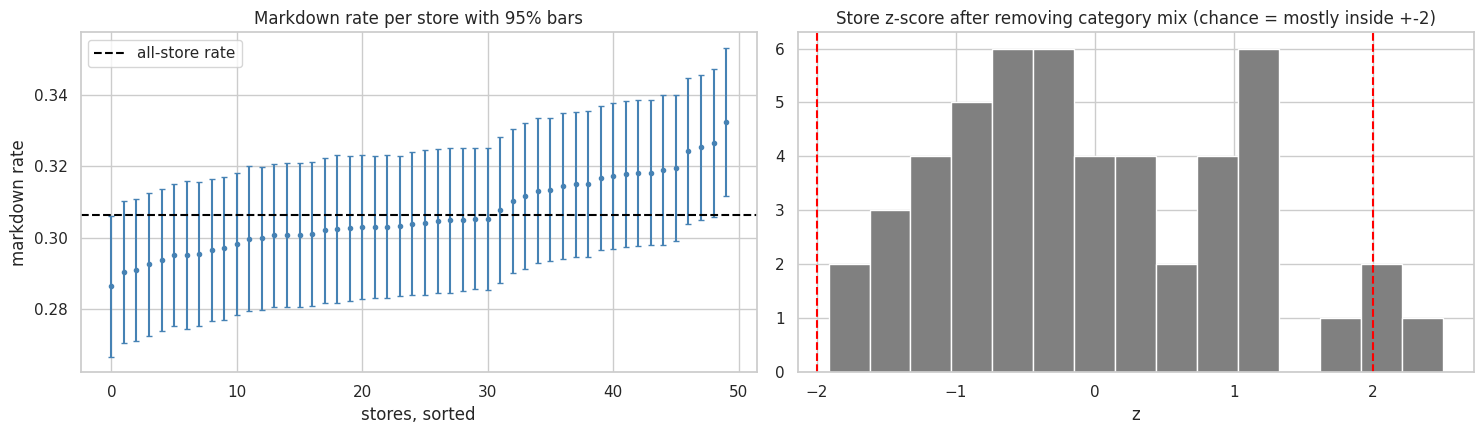

In [8]:
# 1) chi-square across stores
tab = pd.crosstab(df["store_id"], df["markdown_applied"])
chi2, p, dof, _ = stats.chi2_contingency(tab)
v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
print(f"all stores: chi-square p-value = {p:.3g} | Cramer's V = {v:.4f}   (below 0.1 = very weak)")

# 2) real spread versus chance
rate = df.groupby("store_id")["markdown_applied"].agg(["mean", "size"])
p0 = df["markdown_applied"].mean()
chance_sd = np.sqrt(p0 * (1 - p0) / rate["size"]).mean()
print(f"store markdown rates: min {rate['mean'].min():.3f} | max {rate['mean'].max():.3f} | sd {rate['mean'].std():.4f} | sd expected from chance alone {chance_sd:.4f}")

# 3) after removing the category mix: observed vs expected markdowns per store, given its categories
cat_rate = df.groupby("category")["markdown_applied"].mean()
df["_exp"] = df["category"].map(cat_rate)
by = df.groupby("store_id").agg(obs=("markdown_applied", "sum"), exp=("_exp", "sum"), var=("_exp", lambda s: (s * (1 - s)).sum()))
by["z"] = (by["obs"] - by["exp"]) / np.sqrt(by["var"])
chi_adj = (by["z"] ** 2).sum()
p_adj = 1 - stats.chi2.cdf(chi_adj, df=len(by) - 1)
print(f"\nafter removing the category mix: chi-square = {chi_adj:.1f} on {len(by) - 1} df, p-value = {p_adj:.3f}")
print("stores with |z| > 2 (about 5% of 50 = 2 or 3 expected by chance):", int((by['z'].abs() > 2).sum()), "| largest |z|: %.2f" % by["z"].abs().max())
df.drop(columns="_exp", inplace=True)

# how much of the store rate is the category mix?
mix = df.groupby("store_id")["category"].apply(lambda s: s.map(cat_rate).mean())
print("correlation between a store's markdown rate and the rate its category mix predicts: %.2f" % rate["mean"].corr(mix))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
r_sorted = rate.sort_values("mean")
axes[0].errorbar(range(len(r_sorted)), r_sorted["mean"], yerr=1.96 * np.sqrt(r_sorted["mean"] * (1 - r_sorted["mean"]) / r_sorted["size"]), fmt="o", ms=3, color="steelblue", capsize=2)
axes[0].axhline(p0, color="black", ls="--", label="all-store rate"); axes[0].legend()
axes[0].set(title="Markdown rate per store with 95% bars", xlabel="stores, sorted", ylabel="markdown rate")
axes[1].hist(by["z"], bins=15, color="grey"); axes[1].axvline(-2, color="red", ls="--"); axes[1].axvline(2, color="red", ls="--")
axes[1].set(title="Store z-score after removing category mix (chance = mostly inside +-2)", xlabel="z")
plt.tight_layout(); plt.savefig("figures/m2_store_md_store_differences.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading.** Stores do **not** differ in a detectable way. The spread of store markdown rates (sd 0.0104) is the same as pure chance would give (0.0103), the chi-square test gives p = 0.45 with Cramer's V = 0.022, and every store's error bar in the left chart overlaps the all-store line. After removing each store's category mix the result is the same (p = 0.28; 3 stores beyond +-2 against 2 or 3 expected by chance). This confirms the M1 EDA impression that stores are close to the average. Consequence: a store's past markdown rate is a noisy estimate of **one common rate**, not of a real store policy.

## 5. Behaviour of the feature

Three questions: how fast does the rate settle as history grows (and does `K = 20` help), does the strict version differ from the main one, and does the feature say anything about the batch's **own** markdown?

In [9]:
# convergence: how far is the early value from the store's final overall rate?
final_rate = features.groupby("store_id")["markdown_applied"].transform("mean")
bins = pd.cut(features["store_md_prior_n"], [0, 10, 30, 100, 300, 1000, 3000], include_lowest=True)
conv = features.assign(err_raw=(features["store_md_freq_hist"] - final_rate).abs(),
                       err_smooth=(features["store_md_freq_smoothed"] - final_rate).abs(),
                       err_global=(features["store_md_freq_smoothed"].isna() * 0 + p0 - final_rate).abs()).groupby(bins, observed=True) \
            .agg(rows=("err_raw", "size"), err_raw=("err_raw", "mean"), err_smoothed=("err_smooth", "mean"), err_if_global_rate=("err_global", "mean"))
print("mean absolute distance from the store's final overall rate, by number of earlier batches:")
print(conv.round(4).to_string())

# main vs strict vs 90 days
both = features.dropna(subset=["store_md_freq_hist", "store_md_freq_finished"])
print("\nmain vs strict (finished batches only): correlation %.3f | mean absolute difference %.4f | rows compared %d" % (
      both["store_md_freq_hist"].corr(both["store_md_freq_finished"]), (both["store_md_freq_hist"] - both["store_md_freq_finished"]).abs().mean(), len(both)))
b90 = features.dropna(subset=["store_md_freq_hist", "store_md_freq_90d"])
print("main vs 90 days: correlation %.3f | mean absolute difference %.4f" % (b90["store_md_freq_hist"].corr(b90["store_md_freq_90d"]), (b90["store_md_freq_hist"] - b90["store_md_freq_90d"]).abs().mean()))
prior_big = features["store_md_prior_n"] >= 100
print("share of strict-version batches among earlier batches (rows with 100+ earlier batches): %.1f %%" % (100 * (features.loc[prior_big, "store_md_prior_n_finished"] / features.loc[prior_big, "store_md_prior_n"]).mean()))

mean absolute distance from the store's final overall rate, by number of earlier batches:
                   rows  err_raw  err_smoothed  err_if_global_rate
store_md_prior_n                                                  
(-0.001, 10.0]      622   0.1922        0.0416              0.0086
(10.0, 30.0]        996   0.0946        0.0459              0.0084
(30.0, 100.0]      3502   0.0494        0.0365              0.0085
(100.0, 300.0]    10001   0.0272        0.0244              0.0085
(300.0, 1000.0]   34992   0.0141        0.0136              0.0085
(1000.0, 3000.0]  49887   0.0050        0.0050              0.0085

main vs strict (finished batches only): correlation 0.553 | mean absolute difference 0.0340 | rows compared 99448
main vs 90 days: correlation 0.775 | mean absolute difference 0.0175
share of strict-version batches among earlier batches (rows with 100+ earlier batches): 84.6 %


In [10]:
# why does the strict version run higher? look at what has already expired on one example day
t0 = pd.Timestamp("2024-01-01")
earlier = df[df["transaction_date"] < t0].assign(expired=lambda d: d["expiration_date"] < t0)
comp = earlier.groupby("category").agg(share_of_earlier_batches=("record_id", "size"), expired_by_t0=("expired", "mean"), markdown_rate=("markdown_applied", "mean"))
comp["share_of_earlier_batches"] = comp["share_of_earlier_batches"] / comp["share_of_earlier_batches"].sum()
print(f"example day {t0.date()}: batches transacted earlier = {len(earlier):,}, already expired = {earlier['expired'].mean():.1%}")
print(comp.sort_values("expired_by_t0").round(3).to_string())
print("\nmarkdown rate, all earlier batches: %.3f | only already-expired batches: %.3f" % (earlier["markdown_applied"].mean(), earlier.loc[earlier["expired"], "markdown_applied"].mean()))

example day 2024-01-01: batches transacted earlier = 50,014, already expired = 85.9%
                 share_of_earlier_batches  expired_by_t0  markdown_rate
category                                                               
Pharmaceuticals                     0.102          0.277          0.146
Frozen_Meals                        0.100          0.507          0.144
Beverages                           0.101          0.952          0.152
Dairy                               0.099          0.956          0.170
Produce                             0.100          0.974          0.239
Deli                                0.099          0.984          0.281
Meat                                0.100          0.985          0.336
Bakery                              0.099          0.989          0.476
Seafood                             0.099          0.990          0.482
Ready_to_Eat                        0.100          0.992          0.630

markdown rate, all earlier batches: 0.305 | only a

                         rows  AUC vs own markdown_applied    corr
feature                                                           
store_md_freq_hist      99848                       0.5013  0.0026
store_md_freq_smoothed  99852                       0.5012  0.0022
store_md_freq_90d       99848                       0.5018  0.0036
store_md_freq_finished  99448                       0.4997  0.0038

inside categories (rows with 100+ earlier batches): corr(own markdown, store history) = 0.0035
raw (no category removed) on the same rows: 0.0024


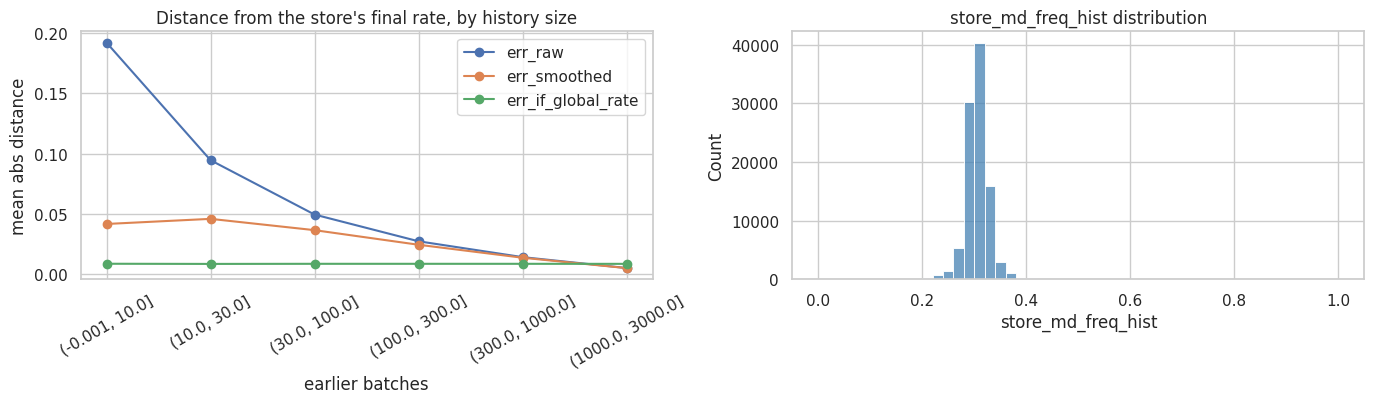

In [11]:
# does the feature say anything about the batch's OWN markdown? (this is what a control variable is for)
y = features["markdown_applied"]
rows = []
for col in ["store_md_freq_hist", "store_md_freq_smoothed", "store_md_freq_90d", "store_md_freq_finished"]:
    ok = features[col].notna()
    rows.append({"feature": col, "rows": int(ok.sum()), "AUC vs own markdown_applied": roc_auc_score(y[ok], features.loc[ok, col]), "corr": y[ok].corr(features.loc[ok, col])})
print(pd.DataFrame(rows).set_index("feature").round(4).to_string())

# same, after the category is taken out (inside a category, does the store history still tell anything?)
ok = features["store_md_freq_hist"].notna() & (features["store_md_prior_n"] >= 100)
res_own  = (y - y.groupby(features["category"]).transform("mean"))[ok]
res_feat = (features["store_md_freq_hist"] - features.groupby("category")["store_md_freq_hist"].transform("mean"))[ok]
print("\ninside categories (rows with 100+ earlier batches): corr(own markdown, store history) = %.4f" % res_own.corr(res_feat))
print("raw (no category removed) on the same rows: %.4f" % y[ok].corr(features.loc[ok, "store_md_freq_hist"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
conv[["err_raw", "err_smoothed", "err_if_global_rate"]].plot(marker="o", ax=axes[0]); axes[0].set(title="Distance from the store's final rate, by history size", xlabel="earlier batches", ylabel="mean abs distance")
axes[0].tick_params(axis="x", rotation=30)
sns.histplot(features["store_md_freq_hist"].dropna(), bins=50, ax=axes[1], color="steelblue"); axes[1].set(title="store_md_freq_hist distribution")
plt.tight_layout(); plt.savefig("figures/m2_store_md_behaviour.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading.**

- **Settling:** with few earlier batches the raw rate is far from the store's final rate (distance 0.19 with 10 or fewer batches), and the smoothed version cuts that to 0.04. But using the all-store rate alone stays at about 0.0085 at every history size, which is better than either until a store has more than 1,000 earlier batches. This is what "stores are all the same" looks like: store history is just noise around the common rate. So for small histories the smoothed version is the safe input, and a larger K would also be reasonable.
- **No information about the batch's own markdown:** AUC is about 0.50 and the correlation is 0.003 to 0.004, also inside categories. This is the expected result of a clean no-lookahead feature on stores that behave alike; it also means nothing about the current batch leaks in.
- **Strict version is not a drop-in replacement:** it correlates only 0.55 with the main feature and runs higher (0.340 against 0.306). The example day shows why: by 2024-01-01 almost all short-life batches have expired (96% to 99%) but only 28% of Pharmaceuticals and 51% of Frozen_Meals, and those two categories mark down least (about 15%). So the expired batches over-represent high-markdown categories. Keep it as a robustness check only.
- **90-day version** follows the main one (correlation 0.78) and adds nothing either.
- **For M3-T05:** use `store_md_freq_hist` as the card defines it, or `store_md_freq_smoothed` when a low-history row matters, always next to `category`, and do not expect the coefficient to be large.

## 6. Ready as a control variable for M3-T05

The table below is the hand-over. The feature uses past rows only, so it needs **no fitting** and the train/test split from M1-T04 does not change it (no value ever uses a later row, so no test information reaches the training rows).

In [12]:
handover = pd.DataFrame([
    ["store_md_freq_hist",     "control (main)",        "0-1",  int(features["store_md_freq_hist"].isna().sum()),     "share of earlier batches of the store with a markdown"],
    ["store_md_freq_smoothed", "control (low-history safe)", "0-1", int(features["store_md_freq_smoothed"].isna().sum()), "same, pulled toward the past all-store rate (K = 20)"],
    ["store_md_prior_n",       "support",               "count", 0,                                                  "how many earlier batches the value rests on"],
    ["store_md_freq_90d",      "optional",              "0-1",  int(features["store_md_freq_90d"].isna().sum()),      "last 90 days only"],
    ["store_md_freq_finished", "robustness",            "0-1",  int(features["store_md_freq_finished"].isna().sum()), "only earlier batches already expired"],
], columns=["column", "role", "range", "empty_rows", "meaning"])
print(handover.to_string(index=False))
print()
print("Use in M3-T05: join on record_id; keep `category` in the same model (markdown rates differ a lot by category);")
print("empty rows (first day of the file) should be dropped or filled with the TRAIN all-store markdown rate, not 0.")

                column                       role range  empty_rows                                               meaning
    store_md_freq_hist             control (main)   0-1         152 share of earlier batches of the store with a markdown
store_md_freq_smoothed control (low-history safe)   0-1         148  same, pulled toward the past all-store rate (K = 20)
      store_md_prior_n                    support count           0           how many earlier batches the value rests on
     store_md_freq_90d                   optional   0-1         152                                     last 90 days only
store_md_freq_finished                 robustness   0-1         552                  only earlier batches already expired

Use in M3-T05: join on record_id; keep `category` in the same model (markdown rates differ a lot by category);
empty rows (first day of the file) should be dropped or filled with the TRAIN all-store markdown rate, not 0.


## 7. Save the new columns

In [13]:
out = features[["record_id", "store_md_prior_n", "store_md_freq_hist", "store_md_freq_smoothed", "store_md_prior_n_90d",
                "store_md_freq_90d", "store_md_prior_n_finished", "store_md_freq_finished"]].sort_values("record_id")
out.to_csv("m2_store_markdown_frequency.csv", index=False)
handover.to_csv("m2_store_markdown_handover.csv", index=False)

summary = {
    "feature": "store-level historical markdown frequency",
    "definition": "markdown batches of the store on strictly earlier days / all batches of the store on strictly earlier days",
    "excluded": "the batch itself and every same-day batch of the store",
    "smoothing_K": K_SMOOTH, "window_days_optional": WINDOW_D, "rows": int(len(out)),
    "empty_main_feature": int(out["store_md_freq_hist"].isna().sum()),
    "store_difference_cramers_v": round(float(v), 4), "store_difference_p": float(p),
    "store_difference_p_after_category_mix": round(float(p_adj), 4),
}
Path("m2_store_markdown_summary.json").write_text(json.dumps(summary, indent=2))
print(out.shape); print(json.dumps(summary, indent=2)); out.head()

(100000, 8)
{
  "feature": "store-level historical markdown frequency",
  "definition": "markdown batches of the store on strictly earlier days / all batches of the store on strictly earlier days",
  "excluded": "the batch itself and every same-day batch of the store",
  "smoothing_K": 20,
  "window_days_optional": 90,
  "rows": 100000,
  "empty_main_feature": 152,
  "store_difference_cramers_v": 0.0223,
  "store_difference_p": 0.4504903847841996,
  "store_difference_p_after_category_mix": 0.2768
}


,record_id,store_md_prior_n,store_md_freq_hist,store_md_freq_smoothed,store_md_prior_n_90d,store_md_freq_90d,store_md_prior_n_finished,store_md_freq_finished
0,1,1744,0.319381,0.319229,246,0.296748,1603,0.336868
1,2,299,0.341137,0.338863,269,0.338290,218,0.389908
2,3,1733,0.321985,0.321803,230,0.317391,1596,0.337093
3,4,941,0.279490,0.280024,251,0.282869,803,0.305106
4,5,584,0.309932,0.309842,242,0.342975,474,0.345992


## 8. Text for the Feature Engineering Summary

In [14]:
f = features
first_day = f["transaction_date"] == f["transaction_date"].min()
ok = f["store_md_freq_hist"].notna() & (f["store_md_prior_n"] >= 100)
text = f"""
**Store-level historical markdown frequency (M2, control variable for M3-T05)**

**Definition.** For a batch of store s on day t: `store_md_freq_hist` = markdown batches of store s on days **before t** / all batches of store s on days before t, with a markdown meaning
`markdown_applied == 1` (identical to `discount_pct > 0` in every row). The batch itself and all same-day batches of the store are excluded because the order inside a day is unknown.
Computed with cumulative sums per store-day minus the day's own totals, so no later row is ever read.

**Companions.** `store_md_prior_n` (earlier batches behind the value), `store_md_freq_smoothed` (adds {K_SMOOTH} imaginary batches at the past all-store rate to calm small samples),
`store_md_freq_90d` (last {WINDOW_D} days only) and `store_md_freq_finished` (only earlier batches that had already expired, the strictest no-lookahead version).

**Empty values.** {int(f['store_md_freq_hist'].isna().sum())} rows have no earlier batch ({int(first_day.sum())} on the first date of the file, the rest on the first day of a store) and are left empty, not 0. {100*(f['store_md_prior_n'] < 20).mean():.1f}% of rows rest on fewer than 20 earlier batches; use the smoothed version or `store_md_prior_n` there.

**Validation.** 400 rows recalculated with a plain loop (all three versions match); a leakage test flips the markdown of every batch of one store-day per store and no changed batch moves its own value while later batches do;
values stay in [0, 1]; empty values occur only where no earlier batch exists.

**What the data say.** Store markdown rates run from {rate['mean'].min():.1%} to {rate['mean'].max():.1%} (overall {p0:.1%}), and their spread ({rate['mean'].std():.4f}) is the same as pure chance would give ({chance_sd:.4f}).
Stores do not differ in a detectable way (chi-square p = {p:.2f}, Cramer's V {v:.3f}); after removing each store's category mix the result is the same (p = {p_adj:.2f}). So the feature is a noisy estimate of one common rate,
and it carries essentially no information about the batch's own markdown (AUC {roc_auc_score(f.loc[ok,'markdown_applied'], f.loc[ok,'store_md_freq_hist']):.3f}). It is valid and leak-free as a control for M3-T05, but should not be expected to change results.
For batches with little history the smoothed version is the safer input.

**Limitation.** As in M2-T02, a markdown on an earlier batch may be applied after day t if that batch was still on the shelf. `store_md_freq_finished` removes this, but it is not a drop-in replacement: it runs higher
(mean {f['store_md_freq_finished'].mean():.3f} against {f['store_md_freq_hist'].mean():.3f}) and correlates only {both['store_md_freq_hist'].corr(both['store_md_freq_finished']):.2f} with the main feature, because the batches that have already expired are mostly short-life, high-markdown categories (Section 5).
In deployment use the markdown history that is available on day t.
"""
print(text)
Path("m2_store_markdown_report_text.md").write_text(text.strip() + "\n", encoding="utf-8")


**Store-level historical markdown frequency (M2, control variable for M3-T05)**

**Definition.** For a batch of store s on day t: `store_md_freq_hist` = markdown batches of store s on days **before t** / all batches of store s on days before t, with a markdown meaning
`markdown_applied == 1` (identical to `discount_pct > 0` in every row). The batch itself and all same-day batches of the store are excluded because the order inside a day is unknown.
Computed with cumulative sums per store-day minus the day's own totals, so no later row is ever read.

**Companions.** `store_md_prior_n` (earlier batches behind the value), `store_md_freq_smoothed` (adds 20 imaginary batches at the past all-store rate to calm small samples),
`store_md_freq_90d` (last 90 days only) and `store_md_freq_finished` (only earlier batches that had already expired, the strictest no-lookahead version).

**Empty values.** 152 rows have no earlier batch (148 on the first date of the file, the rest on the first day of a

2540